# Event Chronicle AI

**German Text Event Classification & Chronology Reconstruction**

This notebook demonstrates a small NLP pipeline that extracts sentences from German text, creates multilingual embeddings, groups similar sentences, detects dates, classifies event types, and records real classifier calls in Arize Phoenix.

> Run the cells from top to bottom in Google Colab. The first run may take several minutes because language and model files need to download.

## 1. Install dependencies

Install the NLP, embedding, classification, date-parsing, and Phoenix packages used in this notebook.

In [1]:
%pip install -q arize-phoenix arize-phoenix-otel spacy sentence-transformers scikit-learn dateparser transformers pandas
!python -m spacy download de_core_news_sm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.
ibis-framework 9.5.0 requires sqlglot<25.21,>=23.4, but you have sqlglot 30.21.0 which is incompatible.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.6/14.6 MB 25.7 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Resta

## 2. Start Phoenix

Start the Phoenix UI before running the model so that the tracing endpoint is available. The Colab proxy URL below provides browser access to the service running on port `6006`.

In [3]:
import phoenix as px

# Reuse an existing Phoenix session if one is already running.
session = px.active_session()

if session is None:
    session = px.launch_app()

if session is not None:
    print("Phoenix is ready.")
    print("Open the Phoenix UI:")
    print(session.url)
else:
    print("Phoenix did not start. Restart the Colab runtime and try again.")

/usr/local/lib/python3.13/dist-packages/pydantic/json_schema.py:2666: PydanticJsonSchemaWarning: Default value <phoenix.db.types.db_helper_types.Undefined object at 0x7e4d91330c20> is not JSON serializable; excluding default from JSON schema [non-serializable-default]
  warnings.warn(message, PydanticJsonSchemaWarning)
<sys>:0: SAWarning: Column-expression-level unary distinct() should not be used outside of an aggregate function. For general 'SELECT DISTINCT' support use select().distinct().


🌍 To view the Phoenix app in your browser, visit https://x6zqbozdd1b1-496ff2e9c6d22116-6006-colab.googleusercontent.com/
📖 For more information on how to use Phoenix, check out https://arize.com/docs/phoenix
Phoenix is ready.
Open the Phoenix UI:
https://x6zqbozdd1b1-496ff2e9c6d22116-6006-colab.googleusercontent.com/


## 3. Configure OpenTelemetry tracing

Register Phoenix as the trace destination and create a tracer for this project. The classifier loop later in the notebook creates one span for each real model call.

In [4]:
from phoenix.otel import register
from opentelemetry import trace

# Send OpenTelemetry traces to the local Phoenix endpoint.
tracer_provider = register(
    endpoint="http://127.0.0.1:6006/v1/traces"
)

# Use a project-specific tracer name to identify this notebook's spans.
tracer = trace.get_tracer("event-chronicle-ai")
print("Phoenix tracing configured for Event Chronicle AI.")

🔭 OpenTelemetry Tracing Details 🔭
|  Phoenix Project: default
|  Span Processor: SimpleSpanProcessor
|  Collector Endpoint: http://127.0.0.1:6006/v1/traces
|  Transport: HTTP + protobuf
|  Transport Headers: {}
|  
|  Using a default SpanProcessor. `add_span_processor` will overwrite this default.
|  
|  ⚠️ WARNING: It is strongly advised to use a BatchSpanProcessor in production environments.
|  
|  `register` has set this TracerProvider as the global OpenTelemetry default.
|  To disable this behavior, call `register` with `set_global_tracer_provider=False`.

Phoenix tracing configured for Event Chronicle AI.


## 4. Prepare the German text

Replace the example below with your own German text if needed. Keeping a small sample makes it easier to inspect the resulting sentences and traces.

In [34]:
text = """

Am 12. März 2022 wurde ein Verdächtiger in Berlin festgenommen.
Am 13. Mai 2024 meldete eine Zeugin ein verdächtiges Fahrzeug in der Nähe des Bahnhofs.
Am 14. Juni 2025 sicherten Ermittler mehrere Dokumente als Beweismaterial.
Am 15. Juli 2026 wurde eine weitere Person zu dem Vorfall befragt.
""".strip()



print(text)

Am 12. März 2022 wurde ein Verdächtiger in Berlin festgenommen.
Am 13. Mai 2024 meldete eine Zeugin ein verdächtiges Fahrzeug in der Nähe des Bahnhofs.
Am 14. Juni 2025 sicherten Ermittler mehrere Dokumente als Beweismaterial.
Am 15. Juli 2026 wurde eine weitere Person zu dem Vorfall befragt.


## 5. Split the text into sentences

Use the small German spaCy model to split the input text into sentences.

In [35]:
import spacy
import pandas as pd

nlp = spacy.load("de_core_news_sm")
doc = nlp(text)
sentences = [sent.text.strip() for sent in doc.sents if sent.text.strip()]

sentences_df = pd.DataFrame({"Satz": sentences})
display(sentences_df)

,Satz
0,Am 12. März 2022 wurde ein Verdächtiger in Ber...
1,Am 13. Mai 2024 meldete eine Zeugin ein verdäc...
2,Am 14. Juni 2025 sicherten Ermittler mehrere D...
3,Am 15. Juli 2026 wurde eine weitere Person zu ...


## 6. Create multilingual embeddings and clusters

Encode each sentence with a multilingual Sentence Transformer, then use KMeans to group sentences with similar vector representations. Cluster IDs are exploratory groupings, not verified event identities.

In [37]:
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans

embedding_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
embeddings = embedding_model.encode(sentences)

# Keep the number of clusters valid even if the input contains only one sentence.
n_clusters = min(3, len(sentences))
if n_clusters == 1:
    cluster_ids = [0] * len(sentences)
else:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    cluster_ids = kmeans.fit_predict(embeddings).tolist()

sentences_df["Cluster"] = cluster_ids
display(sentences_df)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,Satz,Datum,Cluster
0,Am 12. März 2022 wurde ein Verdächtiger in Ber...,2022-03-12,2
1,Am 13. Mai 2024 meldete eine Zeugin ein verdäc...,2024-05-13,0
2,Am 14. Juni 2025 sicherten Ermittler mehrere D...,2025-06-14,1
3,Am 15. Juli 2026 wurde eine weitere Person zu ...,2026-07-15,0


## 7. Extract dates from sentences

Use `dateparser.search.search_dates` to look for date expressions in each sentence. If no date is detected, the `Datum` value remains empty.

In [38]:
from dateparser.search import search_dates

def extract_date(sentence):
    """Return the first date found in a German sentence, or None."""
    matches = search_dates(sentence, languages=["de"])
    if not matches:
        return None
    return matches[0][1].date().isoformat()

sentences_df["Datum"] = sentences_df["Satz"].apply(extract_date)
display(sentences_df[["Datum", "Satz", "Cluster"]])

,Datum,Satz,Cluster
0,2022-03-12,Am 12. März 2022 wurde ein Verdächtiger in Ber...,2
1,2024-05-13,Am 13. Mai 2024 meldete eine Zeugin ein verdäc...,0
2,2025-06-14,Am 14. Juni 2025 sicherten Ermittler mehrere D...,1
3,2026-07-15,Am 15. Juli 2026 wurde eine weitere Person zu ...,0


## 8. Load the event classifier

Load the zero-shot classification pipeline and define the event categories. The model may take a little time to download on the first run.

In [39]:
from transformers import pipeline

classifier = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli"
)

candidate_labels = ["Festnahme", "Hinweis", "Beweismaterial", "Sonstiges"]
print("Classifier ready.")

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Classifier ready.


## 9. Run real classification calls with Phoenix tracing

Each sentence is sent to the actual classifier inside a tracing span. Phoenix records the sentence, model name, predicted category, confidence score, and scores for all candidate categories. This is manual instrumentation around real inference calls, not automatic instrumentation of the entire Transformers library.

In [40]:
import json
from opentelemetry.trace import Status, StatusCode

best_labels = []
best_scores = []
all_category_scores = []

for sentence in sentences_df["Satz"]:
    with tracer.start_as_current_span("real-classifier-inference") as span:
        # Record the input and the model used for this inference call.
        span.set_attribute("input.value", sentence)
        span.set_attribute("model.name", "facebook/bart-large-mnli")
        span.set_attribute("openinference.span.kind", "CHAIN")

        # Run the real model on this sentence.
        result = classifier(sentence, candidate_labels)

        category_scores = {
            label: float(score)
            for label, score in zip(result["labels"], result["scores"])
        }
        output = {
            "category": result["labels"][0],
            "score": float(result["scores"][0]),
            "category_scores": category_scores
        }

        # Store the structured model output on the span for inspection in Phoenix.
        span.set_attribute("output.value", json.dumps(output, ensure_ascii=False))
        span.set_status(Status(StatusCode.OK))

        best_labels.append(result["labels"][0])
        best_scores.append(float(result["scores"][0]))
        all_category_scores.append(category_scores)

# Flush pending traces so they are sent to Phoenix before inspecting the UI.
tracer_provider.force_flush()
print(f"Completed and traced {len(sentences_df)} classifier calls.")

Completed and traced 4 classifier calls.


## 10. Build the final event table

Combine the detected dates, sentence text, cluster IDs, predicted event types, and model scores into one table.

In [41]:
events_df = sentences_df.copy()

# Extract dates if the Datum column does not exist yet.
if "Datum" not in events_df.columns:
    from dateparser.search import search_dates

    def extract_date(sentence):
        matches = search_dates(sentence, languages=["de"])
        if not matches:
            return None
        return matches[0][1].date().isoformat()

    events_df["Datum"] = events_df["Satz"].apply(extract_date)

# Add classification results.
events_df["EventType"] = best_labels
events_df["ScoreType"] = best_scores
events_df["CategoryScores"] = all_category_scores

# Sort dated events chronologically; undated sentences are placed at the end.
events_df["_sort_date"] = pd.to_datetime(
    events_df["Datum"], errors="coerce"
)
events_df = (
    events_df.sort_values("_sort_date", na_position="last")
    .drop(columns="_sort_date")
)

display(events_df.reset_index(drop=True))

,Satz,Datum,Cluster,EventType,ScoreType,CategoryScores
0,Am 12. März 2022 wurde ein Verdächtiger in Ber...,2022-03-12,2,Festnahme,0.831714,"{'Festnahme': 0.8317142724990845, 'Hinweis': 0..."
1,Am 13. Mai 2024 meldete eine Zeugin ein verdäc...,2024-05-13,0,Hinweis,0.363074,"{'Hinweis': 0.3630738854408264, 'Festnahme': 0..."
2,Am 14. Juni 2025 sicherten Ermittler mehrere D...,2025-06-14,1,Beweismaterial,0.935200,"{'Beweismaterial': 0.9351998567581177, 'Sonsti..."
3,Am 15. Juli 2026 wurde eine weitere Person zu ...,2026-07-15,0,Festnahme,0.426774,"{'Festnahme': 0.42677417397499084, 'Sonstiges'..."


In [42]:
events_df_sorted = events_df.copy()

# Convert dates to datetime and exclude sentences without a valid date.
events_df_sorted["Datum"] = pd.to_datetime(
    events_df_sorted["Datum"], errors="coerce"
)
events_df_sorted = events_df_sorted.dropna(subset=["Datum"])
events_df_sorted = events_df_sorted.sort_values("Datum")

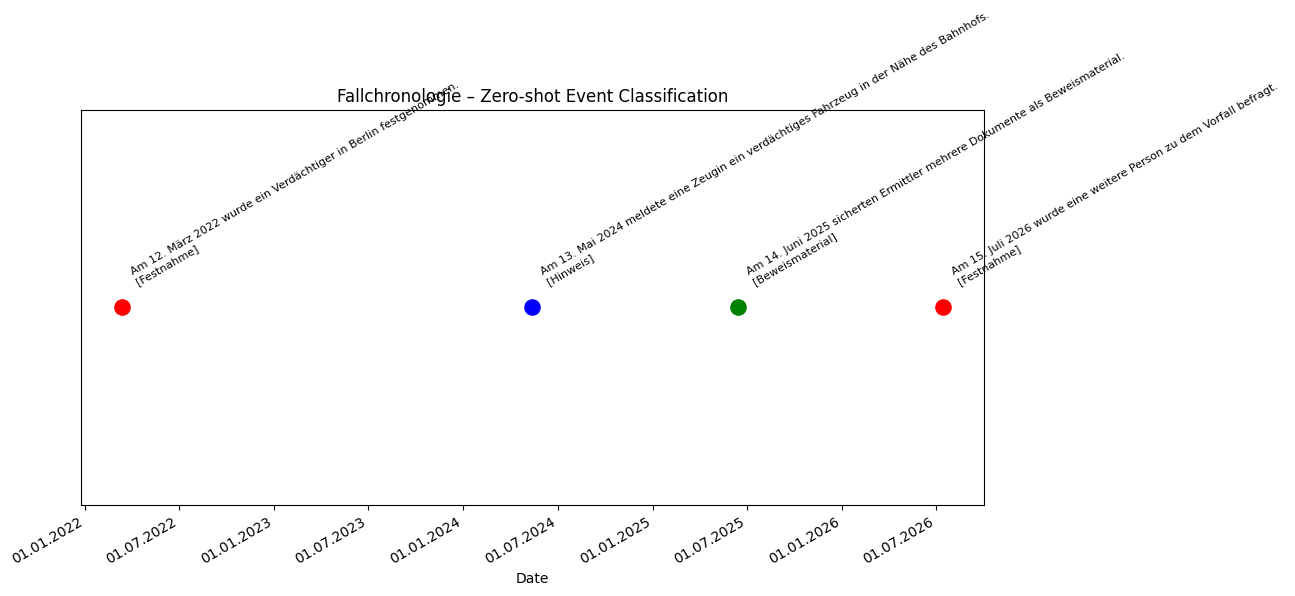

In [43]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# Each event category has its own color.
colors = {
    "Festnahme": "red",
    "Hinweis": "blue",
    "Beweismaterial": "green",
    "Sonstiges": "gray"
}

fig, ax = plt.subplots(figsize=(13, 6))

for _, row in events_df_sorted.iterrows():
    event_date = row["Datum"]
    event_type = row["EventType"]

    ax.scatter(
        event_date,
        1,
        color=colors.get(event_type, "gray"),
        s=120,
        zorder=3
    )

    # Annotate each point with the sentence and predicted category.
    ax.annotate(
        f"{row['Satz']}\n[{event_type}]",
        (event_date, 1),
        xytext=(5, 15),
        textcoords="offset points",
        rotation=30,
        ha="left",
        va="bottom",
        fontsize=8
    )

ax.set_title(
    "Fallchronologie – Zero-shot Event Classification"
)
ax.set_xlabel("Date")
ax.set_yticks([])

# Display dates in a readable format.
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d.%m.%Y")
)
fig.autofmt_xdate()

plt.tight_layout()
plt.show()


##  Recreate the proxy URL for the Phoenix interface for Colab

In [44]:
from google.colab.output import eval_js

# Recreate the proxy URL for the Phoenix interface.
proxy_url = eval_js("google.colab.kernel.proxyPort(6006)")
print(proxy_url)

https://6006-m-s-use1c6-1bnuizz2947vu-c.us-east1.prod.r.colab.dev


## 11. Inspect traces in Phoenix

1. Open the Phoenix URL printed in Section 2.
2. Open the traces view and locate spans named `real-classifier-inference`.
3. Select a span and inspect `input.value`, `model.name`, and `output.value`.
4. Confirm the span status is `OK`.

The exact number of visible spans may include traces from earlier runs in the same Phoenix session. Each time you rerun the classification cell, it creates another set of inference spans.

## Notes and limitations

- This is a demonstration project, not a validated forensic or law-enforcement decision system.
- Zero-shot classification scores are model confidence-like scores, not proof that a category is correct.
- The `facebook/bart-large-mnli` model is primarily English-oriented; for a stronger German-language setup, evaluate a multilingual NLI model before relying on the labels.
- Avoid putting sensitive or personally identifying real case information into a hosted notebook or external monitoring service.